In [4]:
import pandas as pd


In [5]:
df = pd.read_csv("C:/Users/arun/OneDrive/Desktop/project/claims_and_billing.csv")

In [3]:
df

,insurance_provider,Unnamed: 1,claim_id,claim_billing_date,billed_amount,paid_amount,claim_status,denial_reason
0,BCBS,NaN,CLM000001,6/2/2025 0:00,1971.52,0.00,Denied,Claim Billed to Wrong Payer
1,Medicare,NaN,CLM000002,1/5/2025 0:00,1243.80,736.05,Paid,NaN
2,BCBS,NaN,CLM000003,23-02-2025 00:00,4854.11,2676.12,Paid,NaN
3,BCBS,NaN,CLM000004,20-04-2025 00:00,2638.21,1861.39,Paid,NaN
4,BCBS,NaN,NaN,NaN,1046.99,1046.99,Paid,NaN
...,...,...,...,...,...,...,...,...
995,Aetna,NaN,CLM000857,31-03-2025 00:00,4140.50,2979.62,Paid,NaN
996,Medicare,NaN,NaN,NaN,506.14,506.14,Paid,NaN
997,UHC,NaN,CLM000858,17-03-2025 00:00,156.61,121.62,Paid,NaN
998,Aetna,NaN,CLM000859,26-01-2025 00:00,1797.41,1022.30,Paid,NaN


In [1]:
import numpy as np
import scipy
import statsmodels
import sklearn

In [6]:
df.head()

,insurance_provider,Unnamed: 1,claim_id,claim_billing_date,billed_amount,paid_amount,claim_status,denial_reason
0,BCBS,NaN,CLM000001,6/2/2025 0:00,1971.52,0.00,Denied,Claim Billed to Wrong Payer
1,Medicare,NaN,CLM000002,1/5/2025 0:00,1243.80,736.05,Paid,NaN
2,BCBS,NaN,CLM000003,23-02-2025 00:00,4854.11,2676.12,Paid,NaN
3,BCBS,NaN,CLM000004,20-04-2025 00:00,2638.21,1861.39,Paid,NaN
4,BCBS,NaN,NaN,NaN,1046.99,1046.99,Paid,NaN


In [7]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (1000, 8)
Number of rows: 1000
Number of columns: 8


In [8]:
print(df.isnull().sum())



insurance_provider       0
Unnamed: 1            1000
claim_id               140
claim_billing_date     140
billed_amount            0
paid_amount              0
claim_status             0
denial_reason          925
dtype: int64


In [9]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate claim IDs:", df["claim_id"].duplicated().sum())


Duplicate rows: 0
Duplicate claim IDs: 139


In [10]:
print(df["claim_status"].value_counts(dropna=False))


claim_status
Paid      925
Denied     75
Name: count, dtype: int64


In [11]:
print(df["denial_reason"].value_counts(dropna=False))

denial_reason
NaN                                              925
Out-of-Network Provider                            9
Prior Authorization Required                       9
Coordination of Benefits Issue                     8
Medical Necessity Denial                           7
Timely Filing Limit Exceeded                       6
Duplicate Claim                                    5
Expired or Invalid Insurance                       5
Claim Billed to Wrong Payer                        4
Patient Not Eligible on DOS (Date of Service)      4
Incorrect Coding (ICD/CPT/HCPCS)                   4
Missing or Incorrect Information                   4
Invalid Place of Service                           4
Coverage Limit Exceeded                            4
Service Not Covered                                2
Name: count, dtype: int64


In [12]:

total_claims = len(df)

denied_claims = (
    df["claim_status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("denied")
    .sum()
)

denial_rate = (denied_claims / total_claims) * 100

print("Total claims:", total_claims)
print("Denied claims:", denied_claims)
print("Denial rate:", round(denial_rate, 2), "%")


Total claims: 1000
Denied claims: 75
Denial rate: 7.5 %


In [13]:

print("Total billed amount:", df["billed_amount"].sum())

print("Total paid amount:", df["paid_amount"].sum())

print("Average billed amount:", round(df["billed_amount"].mean(), 2))

print("Average paid amount:", round(df["paid_amount"].mean(), 2))


Total billed amount: 1610316.19
Total paid amount: 1040376.25
Average billed amount: 1610.32
Average paid amount: 1040.38


In [14]:

print(
    df.groupby("claim_status")["billed_amount"]
      .mean()
      .round(2)
)


claim_status
Denied    1436.01
Paid      1624.45
Name: billed_amount, dtype: float64


In [15]:

df["claim_billing_date"] = pd.to_datetime(
    df["claim_billing_date"],
    errors="coerce"
)

print(df["claim_billing_date"].dtype)
print(df["claim_billing_date"].head())


datetime64[ns]
0   2025-06-02
1   2025-01-05
2          NaT
3          NaT
4          NaT
Name: claim_billing_date, dtype: datetime64[ns]


In [16]:

print(
    "Missing or invalid billing dates:",
    df["claim_billing_date"].isna().sum()
)


Missing or invalid billing dates: 644


In [17]:

df["claim_month"] = df["claim_billing_date"].dt.to_period("M")

print(df[["claim_billing_date", "claim_month"]].head())


  claim_billing_date claim_month
0         2025-06-02     2025-06
1         2025-01-05     2025-01
2                NaT         NaT
3                NaT         NaT
4                NaT         NaT


In [18]:

df["is_denied"] = (
    df["claim_status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("denied")
)

monthly_analysis = df.groupby("claim_month").agg(
    total_claims=("claim_id", "count"),
    denied_claims=("is_denied", "sum")
)

monthly_analysis["denial_rate_pct"] = (
    monthly_analysis["denied_claims"]
    / monthly_analysis["total_claims"]
    * 100
).round(2)

print(monthly_analysis)


             total_claims  denied_claims  denial_rate_pct
claim_month                                              
2025-01                33              1             3.03
2025-02                15              1             6.67
2025-03                33              0              0.0
2025-04                24              3             12.5
2025-05                36              4            11.11
2025-06                30              6             20.0
2025-07                27              2             7.41
2025-08                25              2              8.0
2025-09                36              2             5.56
2025-10                38              3             7.89
2025-11                27              6            22.22
2025-12                32              3             9.38


In [19]:
# Clean the claim status values
status = (
    df["claim_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)


final_df = df[status.isin(["paid", "denied"])].copy()

# Identify denied claims
final_df["is_denied"] = status[status.isin(["paid", "denied"])].eq("denied")

# Analyse claims by insurance provider
provider_analysis = final_df.groupby("insurance_provider").agg(
    total_decided_claims=("is_denied", "size"),
    denied_claims=("is_denied", "sum")
)

# Calculate denial rate
provider_analysis["denial_rate_pct"] = (
    provider_analysis["denied_claims"]
    / provider_analysis["total_decided_claims"]
    * 100
).round(2)

# Display highest denial rates first
print(provider_analysis.sort_values("denial_rate_pct", ascending=False))

                    total_decided_claims  denied_claims  denial_rate_pct
insurance_provider                                                      
UHC                                  155             19            12.26
Humana                               147             14             9.52
Medicaid                             137             12             8.76
BCBS                                 134             10             7.46
Cigna                                159             10             6.29
Aetna                                135              8             5.93
Medicare                             133              2              1.5


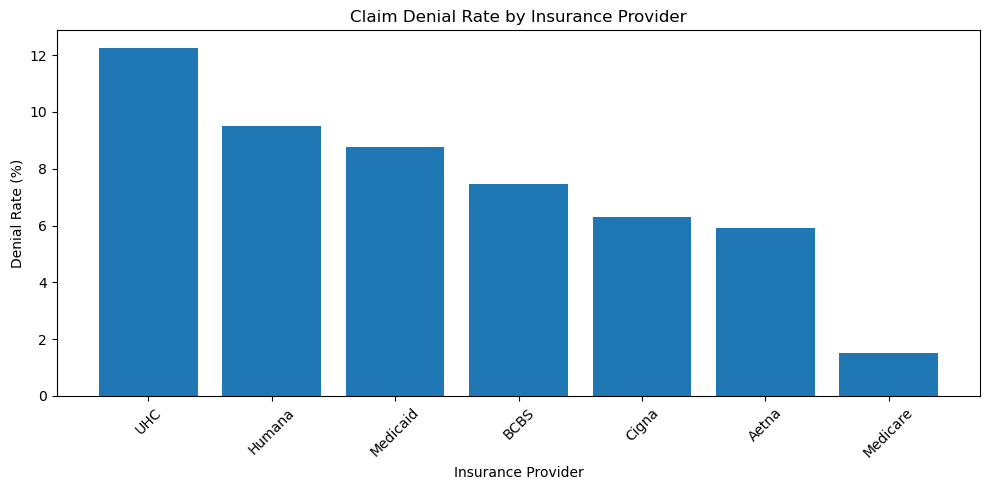

In [20]:
import matplotlib.pyplot as plt

# Sort providers by denial rate
provider_rates = provider_analysis.sort_values(
    "denial_rate_pct", ascending=False
)

# Create the bar chart
plt.figure(figsize=(10, 5))
plt.bar(
    provider_rates.index.astype(str),
    provider_rates["denial_rate_pct"]
)

plt.title("Claim Denial Rate by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Denial Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
# Count claims by denial reason
denial_reasons = (
    df.loc[df["is_denied"], "denial_reason"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
    .value_counts()
)

print("Claims by Denial Reason:")
print(denial_reasons)

Claims by Denial Reason:
denial_reason
Out-of-Network Provider                          9
Prior Authorization Required                     9
Coordination of Benefits Issue                   8
Medical Necessity Denial                         7
Timely Filing Limit Exceeded                     6
Duplicate Claim                                  5
Expired or Invalid Insurance                     5
Claim Billed to Wrong Payer                      4
Patient Not Eligible on DOS (Date of Service)    4
Incorrect Coding (ICD/CPT/HCPCS)                 4
Missing or Incorrect Information                 4
Invalid Place of Service                         4
Coverage Limit Exceeded                          4
Service Not Covered                              2
Name: count, dtype: int64


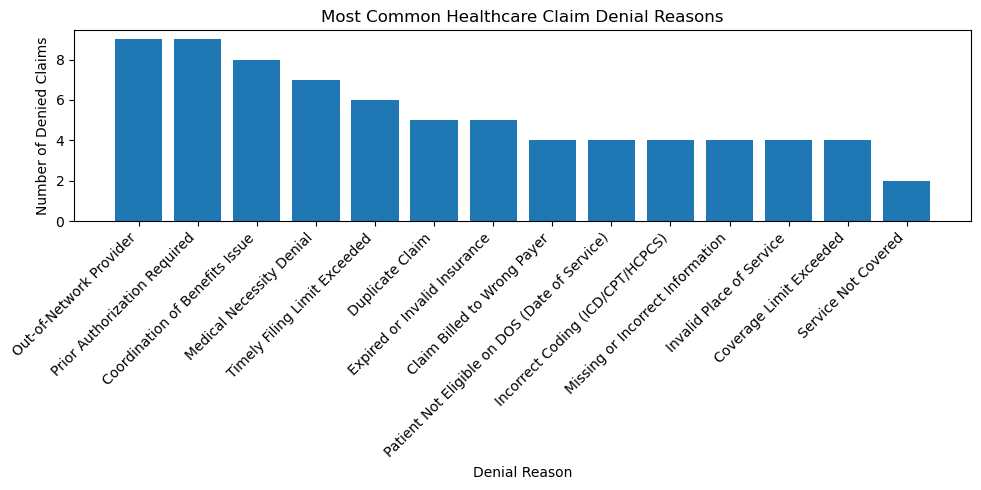

In [22]:
import matplotlib.pyplot as plt

# Get the denial reasons in descending order
denial_reasons = denial_reasons.sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(10, 5))
plt.bar(denial_reasons.index, denial_reasons.values)

plt.title("Most Common Healthcare Claim Denial Reasons")
plt.xlabel("Denial Reason")
plt.ylabel("Number of Denied Claims")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [23]:
# Compare average billed amounts by claim status
amount_comparison = (
    df[df["claim_status"].astype("string").str.strip().str.lower().isin(["paid", "denied"])]
    .assign(
        status_clean=lambda x: (
            x["claim_status"].astype("string").str.strip().str.lower()
        )
    )
    .groupby("status_clean")["billed_amount"]
    .agg(["count", "mean", "median", "sum"])
    .round(2)
)

print(amount_comparison)

              count     mean   median         sum
status_clean                                     
denied           75  1436.01  1197.32   107700.97
paid            925  1624.45  1243.80  1502615.22


In [24]:
# Select denied claims
denied_df = df[df["is_denied"]].copy()

# Calculate financial totals
total_denied_billed = denied_df["billed_amount"].sum()
average_denied_billed = denied_df["billed_amount"].mean()

print("Number of denied claims:", len(denied_df))
print("Total billed amount for denied claims:", round(total_denied_billed, 2))
print("Average billed amount per denied claim:", round(average_denied_billed, 2))

Number of denied claims: 75
Total billed amount for denied claims: 107700.97
Average billed amount per denied claim: 1436.01


In [25]:
from scipy.stats import ttest_ind

# Select billed amounts for each group
paid_amounts = df.loc[
    df["claim_status"].astype("string").str.strip().str.lower().eq("paid"),
    "billed_amount"
].dropna()

denied_amounts = df.loc[
    df["claim_status"].astype("string").str.strip().str.lower().eq("denied"),
    "billed_amount"
].dropna()

# Perform Welch's t-test
t_stat, p_value = ttest_ind(
    paid_amounts,
    denied_amounts,
    equal_var=False
)

print("Paid claims mean:", round(paid_amounts.mean(), 2))
print("Denied claims mean:", round(denied_amounts.mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference detected.")

Paid claims mean: 1624.45
Denied claims mean: 1436.01
T-statistic: 1.4508
P-value: 0.1489
Result: No statistically significant difference detected.


In [26]:
import statsmodels.api as sm

# Select paid and denied claims only
model_df = df[
    df["claim_status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .isin(["paid", "denied"])
].copy()

# Create the binary outcome variable
model_df["denied"] = (
    model_df["claim_status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("denied")
    .astype(int)
)

# Remove rows with missing model values
model_df = model_df.dropna(
    subset=["billed_amount", "denied"]
)

# Define predictor and outcome
X = sm.add_constant(model_df[["billed_amount"]])
y = model_df["denied"]

# Fit the logistic regression model
logit_model = sm.Logit(y, X).fit()

# Display the results
print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.266023
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 denied   No. Observations:                 1000
Model:                          Logit   Df Residuals:                      998
Method:                           MLE   Df Model:                            1
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                0.001358
Time:                        10:18:41   Log-Likelihood:                -266.02
converged:                       True   LL-Null:                       -266.38
Covariance Type:            nonrobust   LLR p-value:                    0.3949
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -2.4137      0.175    -13.816      0.000      -2.756      -2.071
billed_amount -6.509

In [27]:
# Display key logistic regression results

print("Model coefficients:")
print(logit_model.params)

print("\nP-values:")
print(logit_model.pvalues)

print("\nModel converged:", logit_model.mle_retvals["converged"])

Model coefficients:
const           -2.413690
billed_amount   -0.000065
dtype: float64

P-values:
const            2.039020e-43
billed_amount    4.590686e-01
dtype: float64

Model converged: True


In [28]:
import numpy as np

# Calculate odds ratios
odds_ratios = np.exp(logit_model.params)

print("Odds Ratios:")
print(odds_ratios.round(4))

Odds Ratios:
const            0.0895
billed_amount    0.9999
dtype: float64


In [29]:
beta = logit_model.params["billed_amount"]

odds_ratio_1000 = np.exp(beta * 1000)

print(
    "Odds ratio for a ₹1,000 increase:",
    round(odds_ratio_1000, 4)
)

Odds ratio for a ₹1,000 increase: 0.937


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# Prepare the predictor and outcome
X = model_df[["billed_amount"]]
y = model_df["denied"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predict claim status
y_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.925
Precision: 0.0
Recall: 0.0

Confusion Matrix:
[[185   0]
 [ 15   0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96       185
           1       0.00      0.00      0.00        15

    accuracy                           0.93       200
   macro avg       0.46      0.50      0.48       200
weighted avg       0.86      0.93      0.89       200



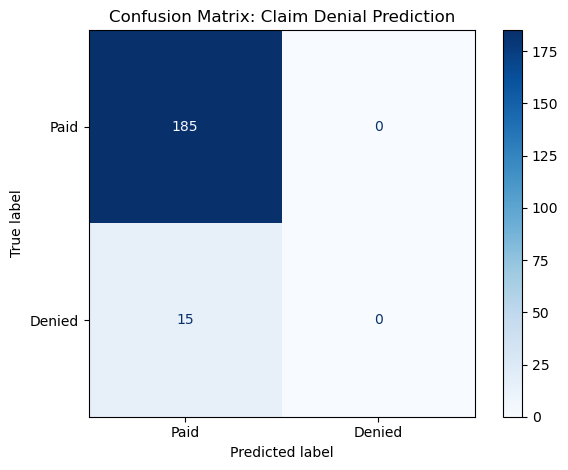

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Display the confusion matrix as a chart
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Paid", "Denied"],
    cmap="Blues"
)

plt.title("Confusion Matrix: Claim Denial Prediction")
plt.tight_layout()
plt.show()

In [32]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Select the predictors and outcome
X = model_df[["billed_amount", "insurance_provider"]].copy()
y = model_df["denied"]

# Convert insurance provider into numerical columns
X = pd.get_dummies(
    X,
    columns=["insurance_provider"],
    drop_first=True,
    dtype=int
)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train the improved model
model_v2 = LogisticRegression(max_iter=1000)
model_v2.fit(X_train, y_train)

# Predict claim denials
y_pred_v2 = model_v2.predict(X_test)

# Evaluate performance
print("Accuracy:", round(accuracy_score(y_test, y_pred_v2), 3))
print("Precision:", round(precision_score(y_test, y_pred_v2, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred_v2, zero_division=0), 3))

Accuracy: 0.925
Precision: 0.0
Recall: 0.0


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Train Model 1 using billed amount only
X1 = model_df[["billed_amount"]]
y = model_df["denied"]

X1_train, X1_test, y_train, y_test = train_test_split(
    X1, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model_v1 = LogisticRegression(max_iter=1000)
model_v1.fit(X1_train, y_train)
pred_v1 = model_v1.predict(X1_test)

# Model 2 predictions already created in Step 30
pred_v2 = model_v2.predict(X_test)

# Compare model performance
comparison = pd.DataFrame({
    "Model": ["Model 1: Billed Amount", "Model 2: Amount + Provider"],
    "Accuracy": [
        accuracy_score(y_test, pred_v1),
        accuracy_score(y_test, pred_v2)
    ],
    "Precision": [
        precision_score(y_test, pred_v1, zero_division=0),
        precision_score(y_test, pred_v2, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_v1, zero_division=0),
        recall_score(y_test, pred_v2, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, pred_v1, zero_division=0),
        f1_score(y_test, pred_v2, zero_division=0)
    ]
}).set_index("Model").round(3)

print(comparison)

                            Accuracy  Precision  Recall  F1 Score
Model                                                            
Model 1: Billed Amount         0.925        0.0     0.0       0.0
Model 2: Amount + Provider     0.925        0.0     0.0       0.0


In [34]:
# Final Claims Denial Analysis Summary

total_claims = len(df)
denied_claims = int(df["is_denied"].sum())

denial_rate = (
    denied_claims / total_claims * 100
    if total_claims > 0 else 0
)

denied_df = df[df["is_denied"]]

total_denied_billed = denied_df["billed_amount"].sum()
average_denied_billed = denied_df["billed_amount"].mean()

print("=" * 45)
print("CLAIMS DENIAL ANALYSIS - PROJECT SUMMARY")
print("=" * 45)

print("Total claims:", total_claims)
print("Denied claims:", denied_claims)
print("Overall denial rate (%):", round(denial_rate, 2))
print("Total billed amount for denied claims:", round(total_denied_billed, 2))
print("Average billed amount for denied claims:", round(average_denied_billed, 2))

print("\nMost common denial reasons:")
print(denial_reasons.head(5))

print("\nDenial rate by insurance provider:")
print(provider_analysis.sort_values(
    "denial_rate_pct", ascending=False
))

print("\nModel comparison:")
print(comparison)

CLAIMS DENIAL ANALYSIS - PROJECT SUMMARY
Total claims: 1000
Denied claims: 75
Overall denial rate (%): 7.5
Total billed amount for denied claims: 107700.97
Average billed amount for denied claims: 1436.01

Most common denial reasons:
denial_reason
Out-of-Network Provider           9
Prior Authorization Required      9
Coordination of Benefits Issue    8
Medical Necessity Denial          7
Timely Filing Limit Exceeded      6
Name: count, dtype: int64

Denial rate by insurance provider:
                    total_decided_claims  denied_claims  denial_rate_pct
insurance_provider                                                      
UHC                                  155             19            12.26
Humana                               147             14             9.52
Medicaid                             137             12             8.76
BCBS                                 134             10             7.46
Cigna                                159             10             6.29

In [35]:
print("Actual test-set claims:")
print(y_test.value_counts())

print("\nModel 1 predictions:")
print(pd.Series(pred_v1).value_counts())

print("\nModel 2 predictions:")
print(pd.Series(pred_v2).value_counts())

Actual test-set claims:
denied
0    185
1     15
Name: count, dtype: int64

Model 1 predictions:
0    200
Name: count, dtype: int64

Model 2 predictions:
0    200
Name: count, dtype: int64


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Use the same training and testing data from Step 30
# X_train, X_test, y_train, y_test

# Create a class-weighted model
model_balanced = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

# Train the model
model_balanced.fit(X_train, y_train)

# Predict test-set claims
y_pred_balanced = model_balanced.predict(X_test)

# Evaluate the model
print("Accuracy:", round(
    accuracy_score(y_test, y_pred_balanced), 3
))
print("Precision:", round(
    precision_score(y_test, y_pred_balanced, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, y_pred_balanced, zero_division=0), 3
))
print("F1 Score:", round(
    f1_score(y_test, y_pred_balanced, zero_division=0), 3
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Paid", "Denied"],
    zero_division=0
))

Accuracy: 0.47
Precision: 0.111
Recall: 0.867
F1 Score: 0.197

Confusion Matrix:
[[ 81 104]
 [  2  13]]

Classification Report:
              precision    recall  f1-score   support

        Paid       0.98      0.44      0.60       185
      Denied       0.11      0.87      0.20        15

    accuracy                           0.47       200
   macro avg       0.54      0.65      0.40       200
weighted avg       0.91      0.47      0.57       200

